## Parameters to change for activity analysis pipeline

- dt (delta time): speed of imaging (seconds/image)
- PSD threshold: the threshold to remove some power from all frequencies in the FFT 
    - e.g. indices = PSD > mean1s * 2 means removing 200% of the mean power of all frequencies in the PSD 
    - note that this threshold will depend on if you downsampled or not (since downsampling removes a lot of frquencies as well)
- rolling average window 
    - e.g. eq = Eq(4/x, y) means that the rolling window is 4s long (window is first determined via seconds and then calculated to match how many frames it would be)
    - this code uses numpy.lib.stride_tricks.sliding_window_view where the window is to the right of each indexed value, via numpy.mean (note that we can also use np.covolve to achieve essentially the same thing)
- ∆F/F window and percentile 
    - Since GCaMP8m bleaches, we use a window (to apply a moving basline across the trace) to mitigate the bleaching effect, calulcated via window_F0 =time*1/dt in the code where time is in seconds for the window size and window_F0 is the time converted to how many frames the window would be. 
    - Percentile is how the F0 (baseline) is determined. F0 can be determined many ways but using percentiles is the simplest. For example, using a high percentile (like the median, 50%) would assume that there's sparse activity so there wouldn't be many transients in the trace to pull the baseline calculation up. For neurons with more transiesnts in their traces, a lower percentile would be more ideal since the "true" baseline would likely be at a lower value in the distribution of fluoresence within the trace.  
- first threshold (z-scoring)
    - Threshold all values via z-scoring, can change z-score threshold from 2-3 (97.72%-99.87% percentile)
- second threshold (event detection)
    - Prominence: how high the ∆F/F of the transient should be at least to be considered a peak (in ∆F/F)
    - Time_apart (aka distance): how much time apart the transients should be from each other (in seconds), otherwise the transient with the higher ∆F/F is chosen only 
    - Time_threshold (aka width): how long each transient should at least be to be considered a peak (in seconds)

Note that for all of these parameters, you'll either have to choose between being more conservative or trying to capture smaller activity and risking high amplitude noise as being interpreted as activity 

In [ ]:
# to run analysis on all columns (cells) of a csv. Output: activity, transient characteristics, and filtered traces 

## set parameters ##
speed_of_imaging = 0.068 
PSD_threshold = 2.5
rolling_mean_window = 4 # in seconds
F0_window = 85 # Moving window size (85 s for dt, in frames/s), quarter of the recording length 
F0_percentile = 40 
first_threshold_zscore = 1.96 # in standard deviations
prominence = 4 # in ∆F/F
time_apart = 1  # in seconds
time_threshold = 1.5 #in seconds


import numpy as np 
import pandas as pd 
from pathlib import Path 
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt 
from sympy import symbols, Eq, solve
from scipy.integrate import simpson
from scipy.ndimage import generic_filter
from scipy import stats
from scipy.signal import find_peaks, peak_widths

movie_path = '/Users/Jeremy/Desktop/compairing noise b:w active and quiet/2026_03_05_Series11_active.csv'

with open(movie_path, 'r') as csv:
     first_line = csv.readline() # this reads the first line and advances the file's internal pointer to the start of the second line.
     your_data = csv.readlines() # reads all remaining lines from the current position to the end of the file into a list of strings stored in your_data

ncol = first_line.count(',') + 1 #count how many ROIs were selected 
print(f"There are {ncol} ROIs in this movie")

other_signals = np.genfromtxt(movie_path, encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,ncol), dtype='f8') #adjust for the number of columns there are, should build code for this  

#speed_of_imaging = float(input("Enter the speed of imaging (seconds/image): ")) #upload the version of the code with this so people don't forget 
#speed_of_imaging = 0.036171
#speed_of_imaging = 0.522
dt = speed_of_imaging
print(f"Speed of imaging is {dt} seconds/image") 
print()

activity_results=[]
num_of_events =[]
freq_of_events = []
length_of_events = []
prominences_of_events = []
counter = 0 
r = 1

for row in other_signals.T: #.T at the end turns columns into rows so that the analysis can analyze them as 'columns'
    n = len(row)
    time_end = n*dt
    t = np.arange(0,time_end,dt)                                             
    num_frames=len(t) 

    #FFT 
    fhat_ = np.fft.fft(row,num_frames)     
    PSD_ = fhat_ * np.conj(fhat_)/num_frames    
    freq_ = (1/(dt*num_frames))*np.arange(num_frames)    
    L = np.arange(1,np.floor(num_frames/2),dtype='int') 

    real_amplitude = np.real(PSD_)
    sqrt_real_amplitude = np.sqrt(real_amplitude)
    mean_amplitude = np.mean(sqrt_real_amplitude)

    #indices = PSD_ > mean_amplitude*5
    indices = PSD_ > mean_amplitude*PSD_threshold   
    PSD_c = PSD_ * indices
    fhat_filt_ = indices * fhat_ 
    ffilt_ = np.fft.ifft(fhat_filt_)
    complex_ifft_output_ = np.array(ffilt_)
    ffilt_array_ = np.real(complex_ifft_output_)

    # Rolling average
    y = symbols('y')
    x = dt 
    eq = Eq(rolling_mean_window/x, y) 
    window_size = solve(eq, y)
    window = window_size[0]
    window_size = round(window)
    window_size = int(window_size)

    windows = sliding_window_view(ffilt_array_, window_shape=window_size)   #can use np.convolve with mode='same' if you want the output to have the same length as the input (by calculating the edges with partial windows)
    rolling_mean = windows.mean(axis=1)

    endpoint = time_end-(window_size-1.00000)*dt
    time = np.arange(0, endpoint, dt) #the last window-1 frames are cut off so we have to adjust the time accordingly

    # ∆F/F
    window_F0 = F0_window*1/dt 
    window_F0 = round(window_F0)
    percentile_value = F0_percentile   
 
    F0 = generic_filter(rolling_mean, function=lambda x: np.percentile(x, percentile_value), size=window_F0)
    dF_over_F = (rolling_mean - F0) / F0*100 # turned into percentage
  
    # First threshold: looking for true events via z-score
    thresholded = dF_over_F
    for i in range(len(thresholded)):
        value = thresholded[i]

        z_score = stats.zscore(dF_over_F)

        if z_score[i] < first_threshold_zscore: 
            thresholded[i] = value * 0  

    # measure other characteristics 
    time_threshold_in_frames = time_threshold/dt
    time_apart_in_frames = time_apart/dt
    peaks, properties = find_peaks(dF_over_F, distance = time_apart, prominence = prominence, width = time_threshold) # distance is the minimum frames between consecutive transients, prominence is how much %∆F/F higher the peak has to be to considered the peak of a true calcium transient, width is how long in frames the signal has to at least be (I converted this to seconds)
    num_of_peaks = len(peaks)
    print(f"ROI {r} has {num_of_peaks} peaks at points {peaks}")

    peak_w = peak_widths(dF_over_F, peaks, rel_height=1) #rel_height=1 means it takes the width at the base of the peak 
    widths_seconds = peak_w[0] * dt
    widths_seconds = widths_seconds.tolist()
    print(f"These events are {widths_seconds} seconds long")

    freq_events = num_of_peaks/time_end
    print(f"The frequency of events in this ROI is {freq_events}/s") 
   
    # find the peak prominences (basically how much ∆F/F the signal changes compared to noise)
    from scipy.signal import peak_prominences
    prominences, left_bases, right_bases = peak_prominences(dF_over_F, peaks) # left and right bases don't matter 
    prominences = prominences.tolist()

    # -- Secondary threshold -- 
    cleaned_trace = dF_over_F.copy() #copy the trace into a new variable 

    # 1. Extract the start and end boundaries for each detected peak
    start = properties['left_ips'].astype(int)
    end = properties['right_ips'].astype(int)

    # 2. Create a boolean mask of regions containing valid transients
    transient_mask = np.zeros_like(dF_over_F, dtype=bool)
    for left, right in zip(start, end):
        transient_mask[left:right+1] = True

    # 3. Define a baseline threshold (e.g., any value above 3x the standard deviation of noise)
    baseline_noise_std = np.std(dF_over_F[~transient_mask]) 
    high_noise_threshold = 3 * baseline_noise_std

    # 4. Find where the noise is high OUTSIDE of our detected transients
    noise_condition = (~transient_mask) & (dF_over_F > high_noise_threshold)

    # 5. Flatten or zero-out the high baseline noise spikes
    cleaned_trace[noise_condition] = 0 

    # save active traces
    if num_of_peaks > 0:
        if counter == 0:
            trace = cleaned_trace # hold the first trace in a different variable to concatenate them later 
            counter += 1 
        elif counter == 1:
            filt_traces = np.column_stack((trace,cleaned_trace))
            counter += 1
        else: 
            filt_traces = np.column_stack((filt_traces,cleaned_trace))
            counter += 1

    # measure activity 
    auc = simpson(cleaned_trace, time) 
    activity = auc/time_end
    activity = activity.tolist()
    print(f"Total activity is {activity} %∆F/F")

    # store number of events, frequency of events, length of events, and prominences of each event in a list 
    activity_results.append(activity) 
    num_of_events.append(num_of_peaks)
    freq_of_events.append(freq_events)
    length_of_events.append(widths_seconds)
    prominences_of_events.append(prominences)

    r+=1
    print()
    

# store these lists in a dataframe 
file_path = Path(movie_path)
filename = file_path.name
filename = filename.removesuffix(".csv")
filename_activity = filename + "_activity_results"
print(f"CSV file will be called {filename_activity}")
data = pd.DataFrame(activity_results)
data.to_csv(filename_activity+'.csv', index=False)

filename_extra = filename + "_extra_results"
print(f"CSV file will be called {filename_extra}")
extra_data = pd.DataFrame({'num_of_events':num_of_events,'freq_of_events (events/s)':freq_of_events, 'length_of_events (s)':length_of_events, 'prominences_of_events (% ∆F/F)':prominences_of_events})
extra_data.to_csv(filename_extra+'.csv', index=True)

# save filtered traces in one csv 

filename_filt_traces = filename + "_filt_traces"
print(f"CSV file will be called {filename_filt_traces}")
np.savetxt(filename_filt_traces+".csv", filt_traces, delimiter=",")





There are 18 ROIs in this movie
Speed of imaging is 0.068 seconds/image

ROI 1 has 1 peaks at points [2096]
These events are [14.620000000000001] seconds long
The frequency of events in this ROI is 0.0029411764705882353/s
Total activity is 0.1035366137114257 %∆F/F

ROI 2 has 2 peaks at points [3956 4880]
These events are [9.044, 5.304] seconds long
The frequency of events in this ROI is 0.0058823529411764705/s
Total activity is 0.17354330013990318 %∆F/F

ROI 3 has 2 peaks at points [ 910 1242]
These events are [8.432, 4.352] seconds long
The frequency of events in this ROI is 0.0058823529411764705/s
Total activity is 0.19335297999537657 %∆F/F

ROI 4 has 2 peaks at points [ 658 1121]
These events are [7.752000000000001, 29.104000000000003] seconds long
The frequency of events in this ROI is 0.0058823529411764705/s
Total activity is 0.345919900270461 %∆F/F

ROI 5 has 1 peaks at points [758]
These events are [12.24] seconds long
The frequency of events in this ROI is 0.0029411764705882353

## to visualize multiple traces at once

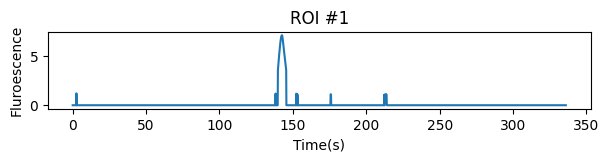

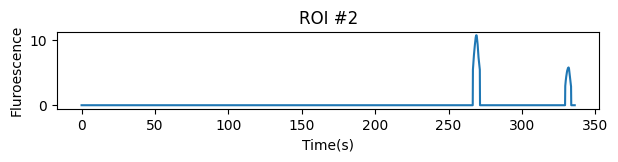

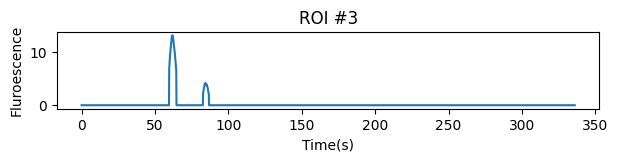

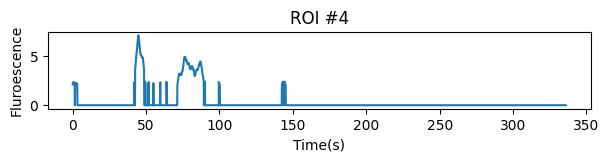

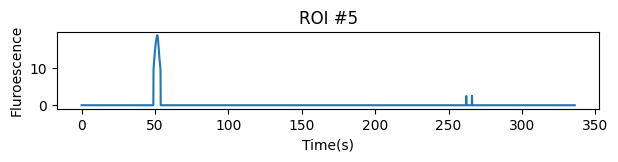

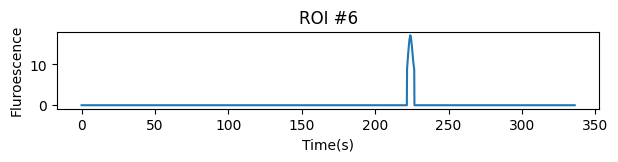

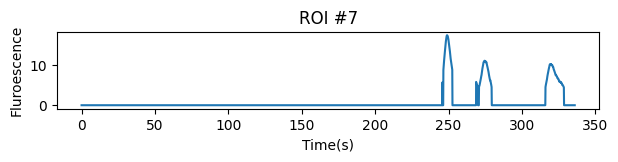

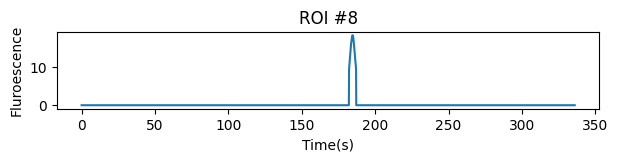

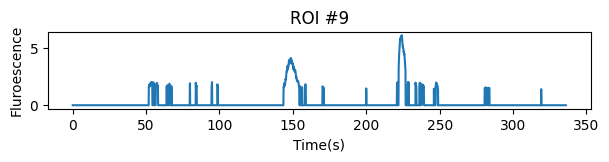

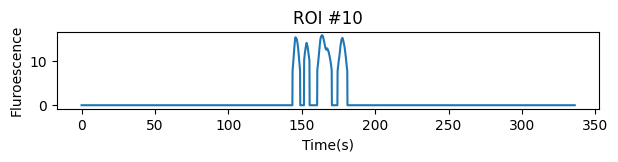

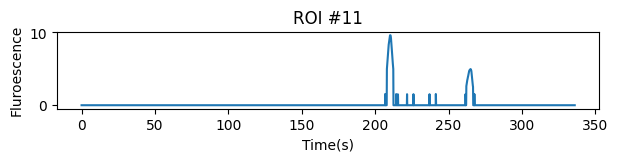

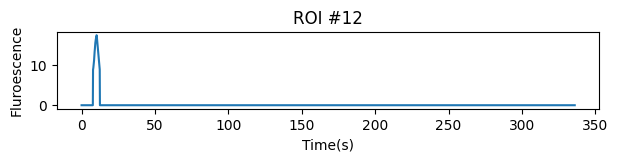

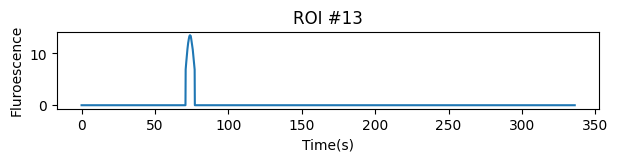

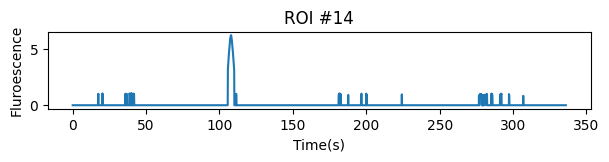

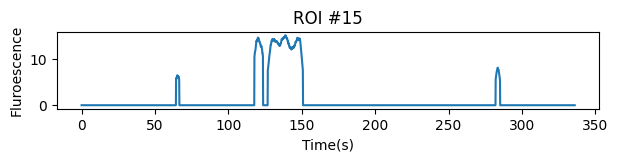

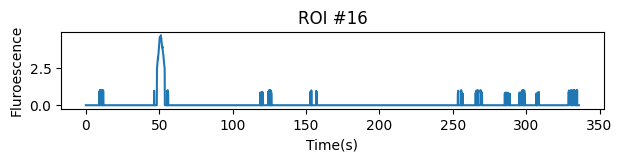

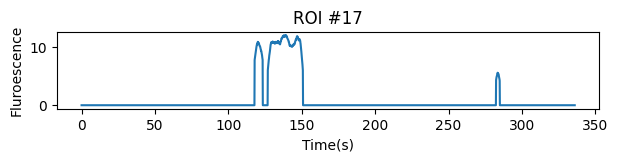

In [254]:
# to look at the trace for each ROI 
import numpy as np 
import matplotlib.pyplot as plt

num_of_rois = 17
other_signals = np.genfromtxt('/Users/Jeremy/Desktop/Files for visual studio /2026_03_05_Series11_active_filt_traces.csv', encoding='utf-8-sig', delimiter = ',', usecols=np.arange(0,num_of_rois), dtype='f8')   
dt = 0.068
                                 
i = 0
# Loop through the data to generate separate figures
while i < num_of_rois: #only using a while loop to name each ROI separately
    for data in other_signals.T: #for loop to call and plot each ROI separately 
        i += 1
        n = len(data)
        time_end = n*dt
        t = np.arange(0,time_end,dt)  
        # Create a new figure and axes in each iteration
        fig, ax = plt.subplots(figsize=(7,1))
    
        ax.plot(t, data)
        ax.set_title(f'ROI #{i}')
        ax.set_xlabel('Time(s)')
        ax.set_ylabel('Fluroescence')




# Calling plt.show() after the loop displays all generated figures
plt.show() 

## Denoising steps 

Speed of imaging is 0.068 seconds/image
There are 5000 frames
This recording is 340.0 seconds long


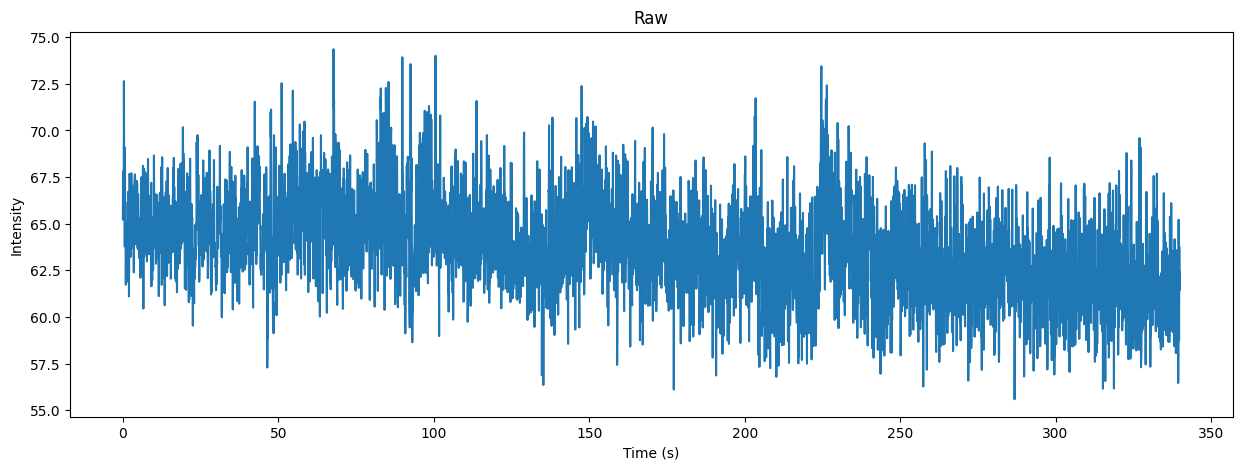

In [255]:
import numpy as np 
import matplotlib.pyplot as plt

#load data with numpy 
# use this function if you want to specify a range of columns to load: usecols(np.arange())
movie_path = '/Users/Jeremy/Desktop/compairing noise b:w active and quiet/2026_03_05_Series11_active.csv'
signal = np.genfromtxt(movie_path, encoding='utf-8-sig', delimiter = ',', usecols=np.arange(8,9), dtype='f8')
 
#speed_of_imaging = float(input("Enter the speed of imaging (seconds/image): ")) #need to input because imaging speed can be different
#dt = speed_of_imaging
#dt = 0.036171
dt = 0.068
#dt = 0.072
#dt = 0.648
print(f"Speed of imaging is {dt} seconds/image") 
n = len(signal) #counting the number of images there are in the time series 
print(f"There are {n} frames")

time_end = n*dt #how long it took to take the time series (in seconds)
print(f"This recording is {time_end} seconds long")
t = np.arange(0,time_end,dt) #creates a range that allows floats (for precision), where 0 is the start, time_end is the stop (which isn't included in the range), and dt is the step size 

plt.figure(figsize=(15, 5)) 
plt.title('Raw')
plt.xlabel("Time (s)")
plt.ylabel("Intensity")
plt.plot(t,signal)
#plt.plot(signal)
plt.savefig("ChR.eps", format="eps",bbox_inches='tight', pad_inches=0.05)

/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


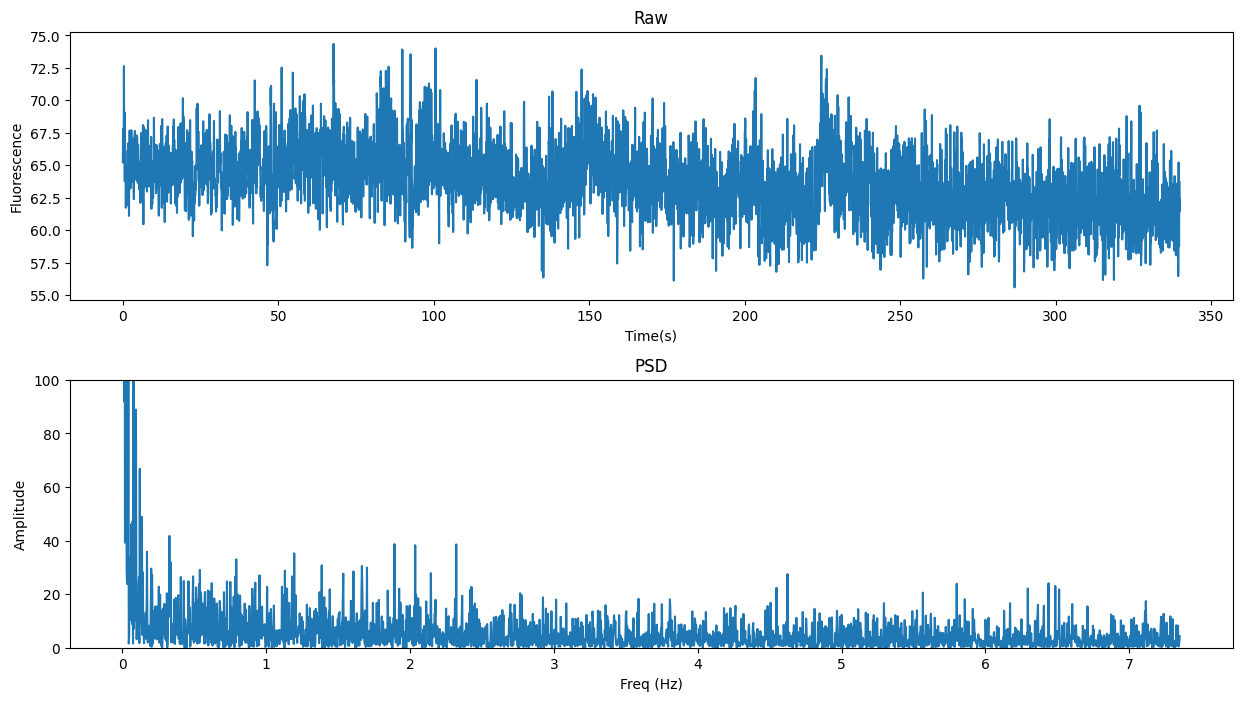

In [256]:
# -- Fast Fourier Transform -- # 

fhat = np.fft.fft(signal,n)     #compute the FFT
PSD = fhat * np.conj(fhat)/n    #Power spectrum density (gives you the magnitude of each fourier coefficient and we'll get a vector of powers at each frequency)
freq = (1/(dt*n))*np.arange(n)    #create an x-axis of frequencies 
L = np.arange(1,np.floor(n/2),dtype='int') #only plot first half (real signals are symmetric)

#plotting raw signal and power spectrum density acquired from FFT
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15,8))
x1=t
x2=freq[L]
y1=signal
y2=PSD[L]

ax1.plot(x1, y1)
ax1.set_title("Raw")
ax1.set_xlabel('Time(s)')
ax1.set_ylabel('Fluorescence')


ax2.plot(x2, y2)
ax2.set_title("PSD")
ax2.set_xlabel("Freq (Hz)")
ax2.set_ylabel("Amplitude")
ax2.set_ylim(0,100)


plt.subplots_adjust(hspace=0.3)


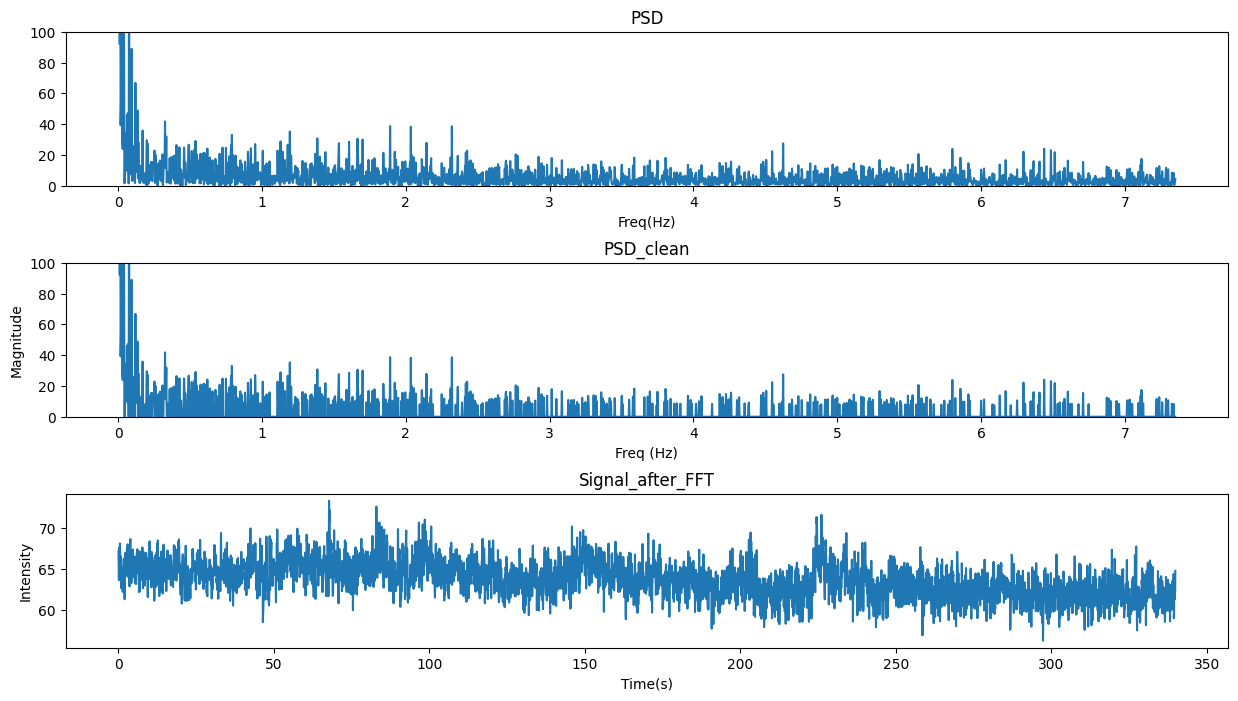

In [257]:
# -- Remove low power noise from all frequencies -- #

# Determine mean amplitude of PSD
power_spectrum_density = np.real(PSD) #takes only real values from the FFT
amplitude = np.sqrt(power_spectrum_density) #need to square root PSD since it is technically fhat^2
mean1s = np.mean(amplitude) #mean amplitude of power from PSD 

# Determine threshold value (can be a right above the noise floor or using a quartile approach)  
indices = PSD > mean1s * 2.5 #threshold PSD to 250% times the mean, the lower amplitude noise out (the noise that sticks out more)

# Set all FFT coefficients below the threshold to 0 and perform a reverse FFT to reconstruct signal without excluded frequencies
PSD_clean = PSD * indices
fhat_filt = indices * fhat 
ffilt = np.fft.ifft(fhat_filt)
complex_ifft_output = np.array(ffilt)
float_array = np.real(complex_ifft_output)

#np.savetxt('ffilt.csv', float_array, delimiter=',') #to save filtered signal 

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15,8))
x1=freq[L]
x2=t
y1=PSD[L]
y2=PSD_clean[L]
y3=ffilt        #can input float_array as well but output seems the same so I'm not sure what the difference is 

ax1.plot(x1, y1)
ax1.set_title("PSD")
ax1.set_xlabel('Freq(Hz)')
ax1.set_ylim(0,100)

ax2.plot(x1, y2)
ax2.set_title("PSD_clean")
ax2.set_xlabel("Freq (Hz)")
ax2.set_ylabel("Magnitude")
ax2.set_ylim(0,100)

ax3.plot(x2, y3)
ax3.set_title('Signal_after_FFT')
ax3.set_xlabel('Time(s)')
ax3.set_ylabel('Intensity')


plt.subplots_adjust(hspace=0.5)

/var/folders/l6/v6vc0z010wn87j21gw8frxb80000gn/T/ipykernel_94004/1486651517.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


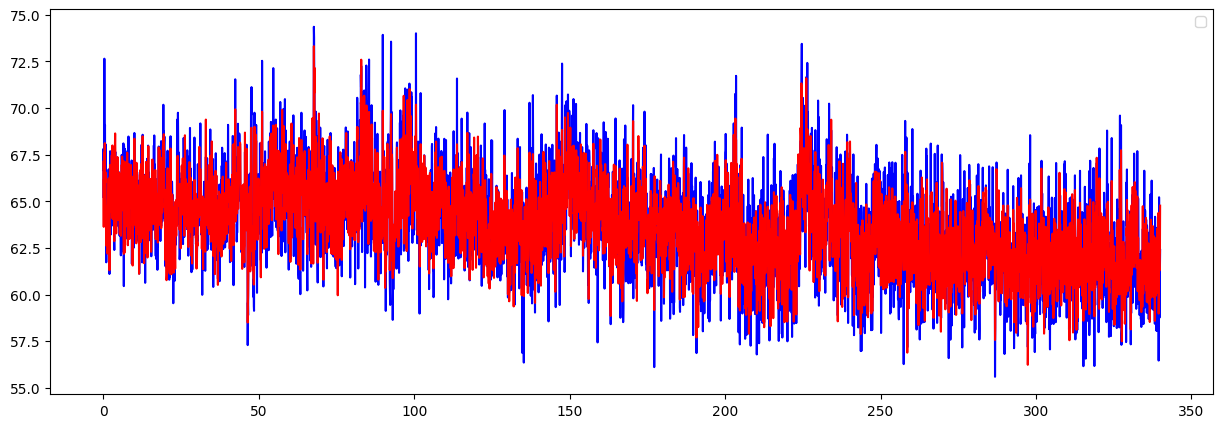

In [258]:
# seeing how much noise the FFT removes  

plt.figure(figsize=(15, 5)) 
plt.plot(t,signal,color='blue')
plt.plot(t,ffilt,color='red')
plt.legend()
plt.show()


The window size for rolling average is 59
4942 frames in the signal averaged by rolling window
Endpoint is 336.056s
4942 time points


Text(0, 0.5, 'Fluorescence')

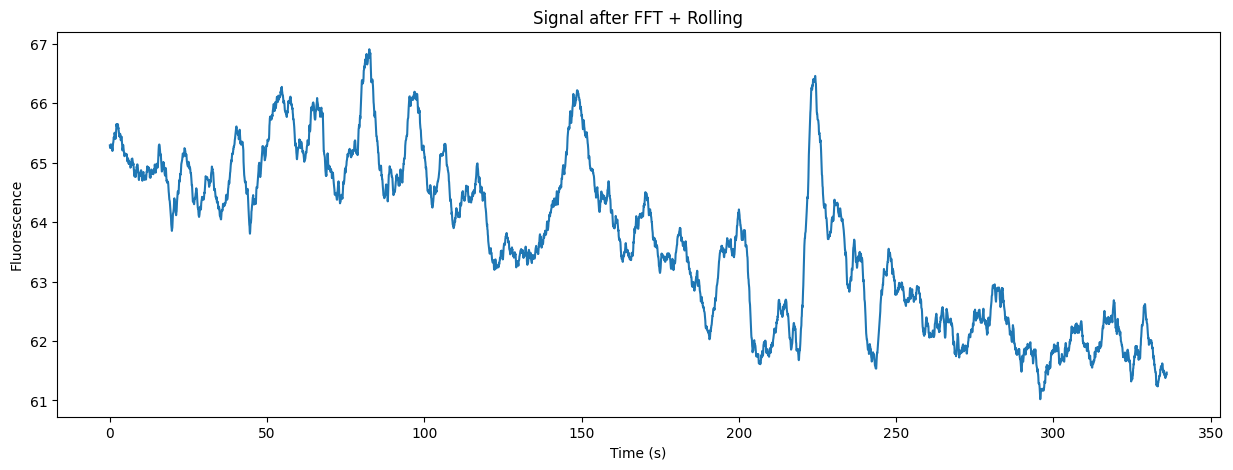

In [259]:
#Rolling average after FFT with Numpy

#make window size dependent on dt, aka images per second 
from sympy import symbols, Eq, solve 

y = symbols('y')
x = dt 
eq = Eq(4/x, y) #window size is based on time constant of 4 seconds
window_size = solve(eq, y)
window = window_size[0]
window_size = round(window) #need to round window size to nearest whole number 
window_size = int(window_size) #need to convert float to integer 
print(f"The window size for rolling average is {window_size}")
#rolling_mean = np.convolve(float_array, np.ones(window_size)/window_size, mode='valid')    #simpler rolling mean 

from numpy.lib.stride_tricks import sliding_window_view
windows = sliding_window_view(float_array, window_shape=window_size)    #can use np.convolve with mode='same' if you want the output to have the same length as the input (by calculating the edges with partial windows)
rolling_mean = windows.mean(axis=1) # axis=1 means that the window is applied across columns, or horizontally 

print(f"{len(rolling_mean)} frames in the signal averaged by rolling window")

endpoint = time_end-(window_size-1.00000)*dt 
print(f"Endpoint is {endpoint}s") 

time = np.arange(0, endpoint, dt) #the last window-1 frames are cut off so we have to adjust the time accordingly
print(f"{len(time)} time points")

plt.figure(figsize=(15, 5)) 
plt.plot (time, rolling_mean)
plt.title('Signal after FFT + Rolling')
plt.xlabel("Time (s)")
plt.ylabel("Fluorescence")
#plt.savefig("GABA2.eps", format="eps",bbox_inches='tight', pad_inches=0.05)


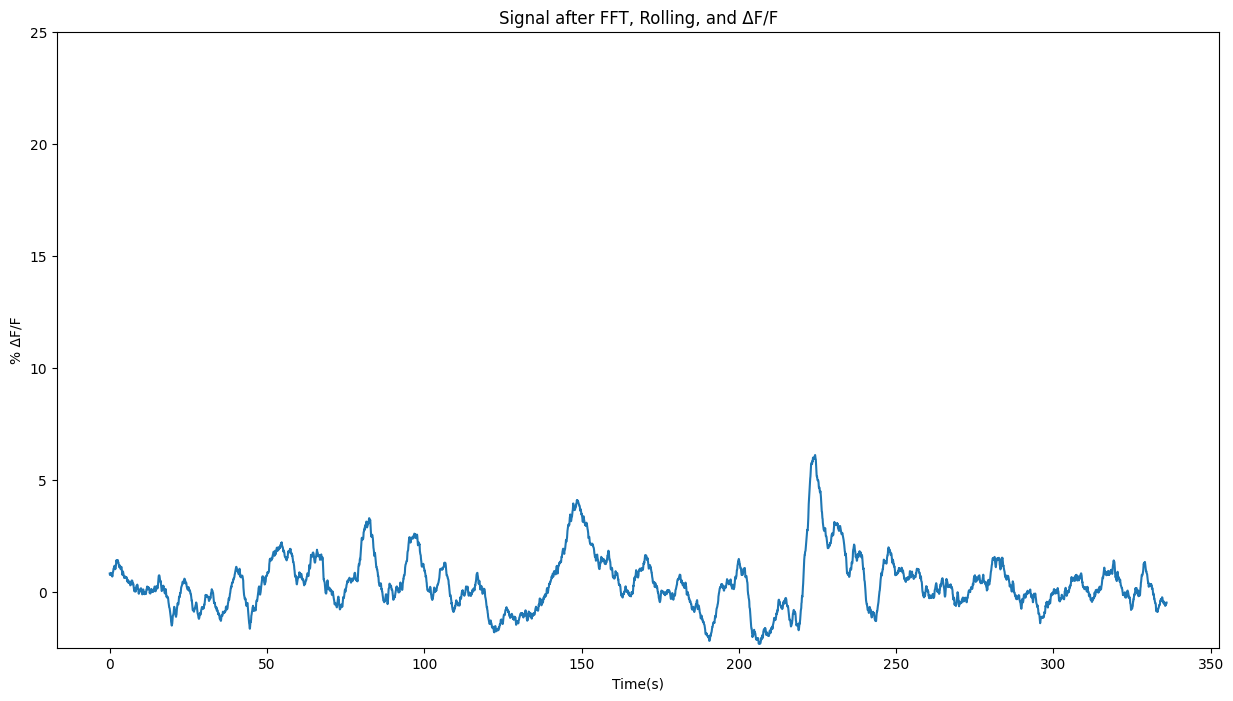

In [267]:
# first compute F0 (baseline fluorescence) using moving percentile, better for when there's slow drifts in baseline fluroscence than using a static median
    # also consider that baseline and background are different things, background is confounding noise 
# then dF/F
from scipy.ndimage import generic_filter

#parameters
#window_F0 = endpoint/(4*dt)
window_F0 =85*1/dt # Moving window size (85s window,  dt, in frames/s)
window_F0 = round(window_F0)
percentile_value = 40 # 40th percentile

#apply moving percentage filter 
F0 = generic_filter(rolling_mean, function=lambda x: np.percentile(x, percentile_value), size=window_F0, mode='reflect')

#noramlize data with F0 
dF_over_F = (rolling_mean - F0) / F0*100 # turned into percentage

fig, ax = plt.subplots(1,1, figsize=(15,8))                                    
x = time
y=dF_over_F
ax.plot(x,y)
ax.set_title('Signal after FFT, Rolling, and \u0394F/F')
ax.set_xlabel('Time(s)')
ax.set_ylabel('% \u0394F/F')
plt.ylim(-2.5,25)
plt.savefig("Cluster3.eps", format="eps",bbox_inches='tight', pad_inches=0.05)
plt.show()

dF = np.copy(dF_over_F) # need to create an independent copy of the variable to compare the arrays in the same cell for the next cell 


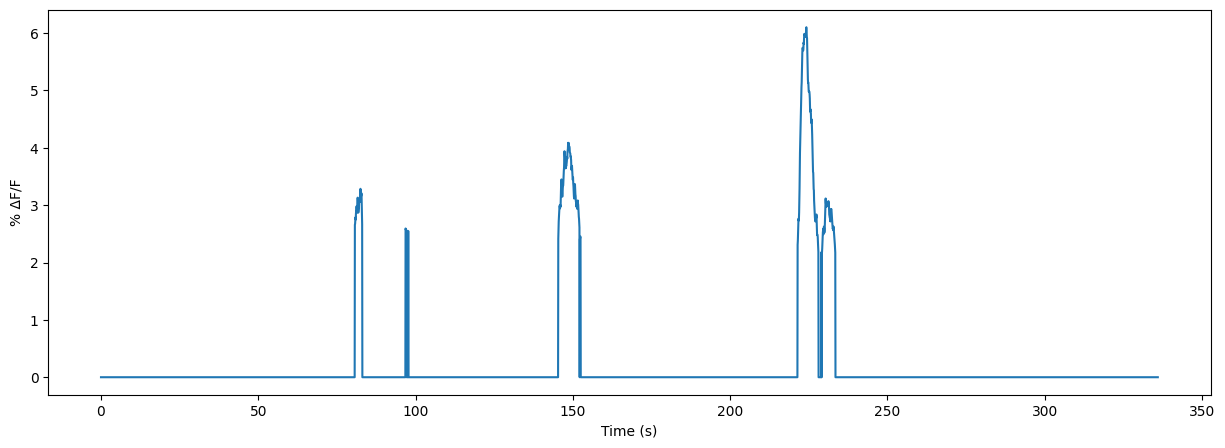

In [268]:
# event detection: applying a statistical significance threshold with z-scoring


from scipy import stats 

for i in range(len(dF_over_F)):
    value = dF_over_F[i]

    z_score = stats.zscore(dF_over_F)

    if z_score[i] < 1.96: #1 standard deviations
        dF_over_F[i] = value * 0  #values below threshold turns to 0, cuts off the feet of signal but this is ok  



plt.figure(figsize=(15, 5)) 
plt.plot (time, dF_over_F)
plt.xlabel("Time (s)")
plt.ylabel("% \u0394F/F")
#plt.savefig("2026_03_05_S11_quiet_neuron2_background", format="eps")

plt.show()



This signal has 2 peaks at points [2184 3298]
These events are [6.868 6.732] seconds long
The frequency of events in this ROI is 0.0058823529411764705/s
The prominence of the signals are [5.90153201 7.5072466 ]


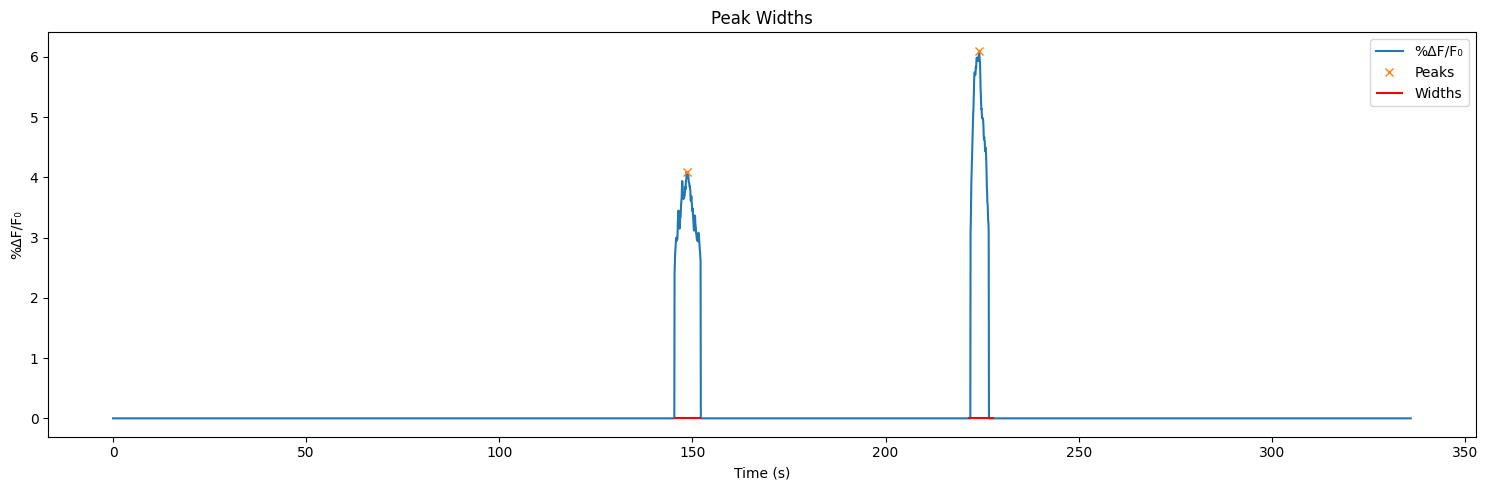

In [269]:
# -- Event detection with peaks and lengths -- 

from scipy.signal import find_peaks, peak_widths, peak_prominences

# parameters 
time_threshold = 1.5/dt # means the transient/peak has to be at least 1.5s long to be detected 
time_apart = 1/dt # means the time in between transients/peaks has to be at least 1s long for both to be detected (otherwise the one with higher prominence is detected)
prominence = 4

# function to detect calcium transients
peaks, properties = find_peaks(dF_over_F, distance = time_apart, prominence = prominence, width = time_threshold) # distance is the minimum frames between consecutive transients, prominence is how much %∆F/F higher the peak has to be to considered the peak of a true calcium transient (for this, I use it to prevent the function from measuring multiple peaks within one transient but normally is a type of thresholding method), width is the min lenght of peak which is set at 1 second
num_of_peaks = len(peaks)
print(f"This signal has {num_of_peaks} peaks at points {peaks}")

# output of find_peaks function 
peak_w = peak_widths(dF_over_F, peaks, rel_height=1) #rel_height=1 means it takes the width at the base of the peak 
widths_seconds = peak_w[0] * dt
print(f"These events are {widths_seconds} seconds long")

freq_events = num_of_peaks/time_end
print(f"The frequency of events in this ROI is {freq_events}/s") 

prominences,_,_ = peak_prominences(dF, peaks) 

print(f"The prominence of the signals are {prominences}")

# -- Clean High Noise Outside of Peaks (secondary threshold)-- #
cleaned_trace = dF_over_F.copy() #copy the trace into a new variable 

# 1. Extract the start and end boundaries for each detected peak
start = properties['left_ips'].astype(int)
end = properties['right_ips'].astype(int)

# 2. Create a boolean mask of regions containing valid transients
transient_mask = np.zeros_like(dF_over_F, dtype=bool)
for left, right in zip(start, end):
    transient_mask[left:right+1] = True

# 3. Define a baseline threshold (e.g., any value above 3x the standard deviation of noise)
baseline_noise_std = np.std(dF_over_F[~transient_mask]) 
high_noise_threshold = 3 * baseline_noise_std

# 4. Find where the noise is high OUTSIDE of our detected transients
noise_condition = (~transient_mask) & (dF_over_F > high_noise_threshold)

# 5. Flatten or zero-out the high baseline noise spikes
cleaned_trace[noise_condition] = 0 


plt.figure(figsize=(15, 5)) 
plt.plot(time, cleaned_trace, label='%ΔF/F₀')
plt.plot(time[peaks], cleaned_trace[peaks], "x", label='Peaks')
plt.hlines(peak_w[1], t[peak_w[2].astype(int)], t[peak_w[3].astype(int)],
           color="red", label='Widths')

plt.xlabel("Time (s)")
plt.ylabel("%ΔF/F₀")
plt.title("Peak Widths")
plt.legend()
plt.tight_layout()
plt.show()

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


AUC is 87.26916043088411 and the total activity is 0.2566740012673062 %∆F/F


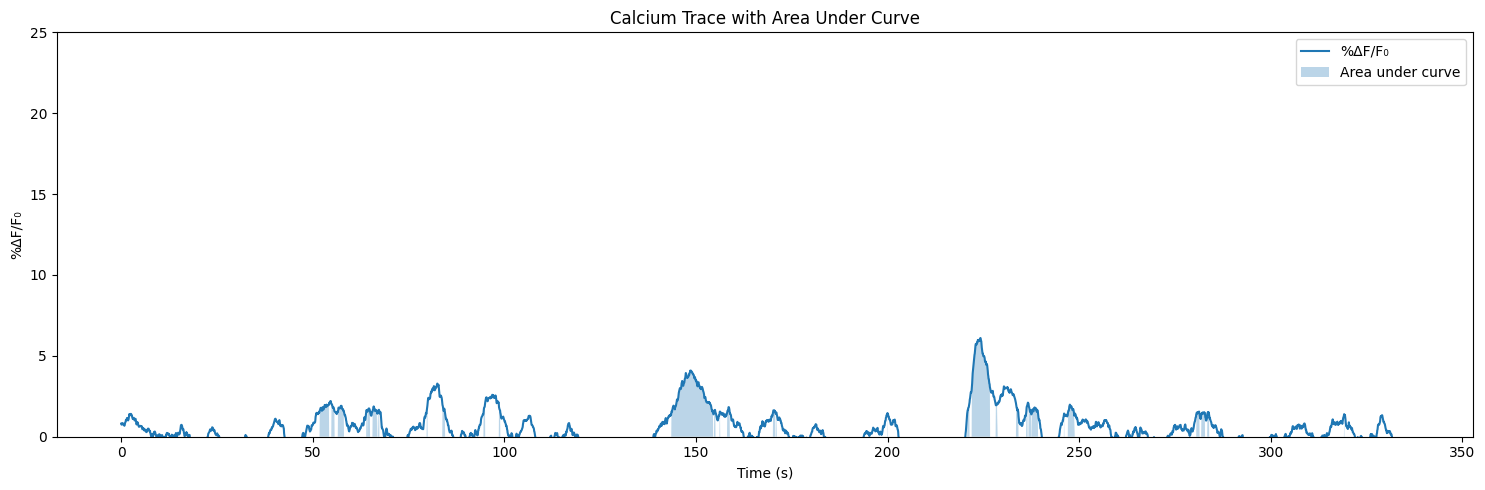

In [263]:
# finding activity via AUC
from scipy.integrate import simpson


t = np.arange(0, endpoint, dt)
auc = simpson(cleaned_trace, t)
activity = auc/time_end
print(f"AUC is {auc} and the total activity is {activity} %∆F/F")

plt.figure(figsize=(15, 5)) 
plt.plot(t, dF, label='%ΔF/F₀', )
plt.fill_between(t, cleaned_trace, alpha=0.3, label='Area under curve') #alpha used for blending (values from 0-1) 
plt.xlabel('Time (s)')
plt.ylabel('%ΔF/F₀')
plt.title('Calcium Trace with Area Under Curve')
plt.legend()
plt.tight_layout()
plt.ylim(0,25)

plt.savefig("GABAneuron1.eps", format="eps")

plt.show()

In [75]:
'''
# store number of events, frequency of events, length of events, and prominences of each event in a list 
import pandas as pd 

num_of_events =[]
freq_of_events = []
length_of_events = []
prominences_of_events = []

num_of_events.append(num_of_peaks)
freq_of_events.append(freq_events)
length_of_events.append(widths_seconds)
prominences_of_events.append(prominences)

# store these lists in a dataframe 
file_path = Path(movie_path)
filename = file_path.name
filename = filename.removesuffix(".csv")
filename = filename + "_extraresults"
print(f"CSV file will be called {filename}")

extra_data = pd.DataFrame({'num_of_events':num_of_events,'freq_of_events (events/s)':freq_of_events, 'length_of_events (s)':length_of_events, 'prominences_of_events (% ∆F/F)':prominences_of_events})
extra_data.to_csv(filename+'.csv', index=True)
'''

'\n# store number of events, frequency of events, length of events, and prominences of each event in a list \nimport pandas as pd \n\nnum_of_events =[]\nfreq_of_events = []\nlength_of_events = []\nprominences_of_events = []\n\nnum_of_events.append(num_of_peaks)\nfreq_of_events.append(freq_events)\nlength_of_events.append(widths_seconds)\nprominences_of_events.append(prominences)\n\n# store these lists in a dataframe \nfile_path = Path(movie_path)\nfilename = file_path.name\nfilename = filename.removesuffix(".csv")\nfilename = filename + "_extraresults"\nprint(f"CSV file will be called {filename}")\n\nextra_data = pd.DataFrame({\'num_of_events\':num_of_events,\'freq_of_events (events/s)\':freq_of_events, \'length_of_events (s)\':length_of_events, \'prominences_of_events (% ∆F/F)\':prominences_of_events})\nextra_data.to_csv(filename+\'.csv\', index=True)\n'